# Uczenie Maszynowe - LIME w wyjaśnianiu sieci neuronowych

Biblioteka LIME: https://github.com/marcotcr/lime (Dokumentacja API: https://lime-ml.readthedocs.io/en/latest/)

# Wprowadzenie - pakiety

Niezbędne pakiety i moduły na potrzeby wprowadzenia

In [1]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import torch
from lime import lime_image
from PIL import Image
from skimage.segmentation import mark_boundaries
from torchvision import models
import torchvision.transforms.v2 as transforms

c:\Users\Lukasz\Documents\GitHub\machine-learning-s9\lab04\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Wprowadzenie - funkcje pomocnicze

Funkcja do wczytywania wskazanego obrazka oraz konwersji do palety RGB.

In [2]:
def get_image(path):
    with open(path, 'rb') as f:
        with Image.open(f) as img:
            return img.convert('RGB')

Funkcja do przekształcania obrazka (zwróconego przez funkcję `get_image`) w tensor, akceptowalny na wejściu sieci neronowej.

In [3]:
def image_to_tensor(img):    
    transformer = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.CenterCrop(224),
        transforms.ToImage(),
        transforms.ToDtype(torch.float32, scale=True),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225])
    ])  
    return transformer(img).unsqueeze(0)

Funkcja używana przez LIME, przyjmuje na wejściu zbiór obrazków, a zwraca prawdopodobieństwa klas. Należy ją przekazać do `lime_image.LimeImageExplainer().explain_instance` przy użyciu `partial`, jako `partial(predict_batch, <model>)`, gdzie modelem w naszym wypadku będą sieci neuronowe. Przykłady użycia są zawarte w tym notebooku.

In [4]:
def predict_batch(model, images):
    model.eval()
    transformer = transforms.Compose([
        transforms.ToImage(),
        transforms.ToDtype(torch.float32, scale=True),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]) 
    ])   
    
    model.eval()
    batch = torch.stack(tuple(transformer(i) for i in images), dim=0)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    batch = batch.to(device)
    
    logits = model(batch)
    probas = torch.nn.functional.softmax(logits, dim=1)
    return probas.detach().cpu().numpy()

Funkcja, która przekształca obrazek w format akceptowany na wejściu przez LIME. Przykłady użycia są zawarte w tym notebooku.

In [5]:
def lime_transformer(image):
    transformer = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.CenterCrop(224)
    ])
    return np.array(transformer(image))

LIME jest głównie wykorzystywane do **wyjaśniania** predykcji tzw. czarnych skrzynek, czyli modeli nieinterpretowalnych. Idealnymi kandydatami są Głębokie Sieci Neuronowe, dlatego spróbujemy wyjaśnić niektóre predykcje gotowych modeli.

# Model Inception-v3 - przygotowanie danych
https://arxiv.org/abs/1512.00567

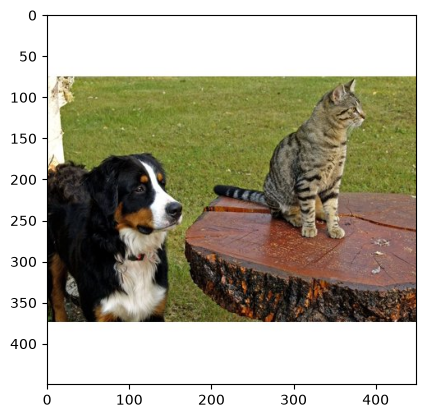

In [6]:
image_to_classify = get_image("./data/dogs.png")
plt.imshow(image_to_classify)

In [7]:
img_tensor = image_to_tensor(image_to_classify)

### **Załadowanie pretrenowanego modelu**

In [8]:
weights = models.Inception_V3_Weights.DEFAULT
inception_v3 = models.inception_v3(weights=weights)

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to C:\Users\Lukasz/.cache\torch\hub\checkpoints\inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:01<00:00, 72.1MB/s] 


Lista `class_names` zawiera przypisanie klas obrazków do indeksów. Jest to istotne, ponieważ zwracane wyniki (np. wartości funkcji logit na wyjściu sieci neuronowych) wykorzystują to, zwracając wyniki w zadanej kolejności.

In [9]:
class_names = weights.meta['categories']

### **Predykcja**

In [10]:
inception_v3.eval()
logits = inception_v3(img_tensor)

Zwróć uwagę, że model zwraca wartości funkcji logit, a nie prawdopodobieństwa klas, dlatego wyniki trzeba przetworzyć (np. przy użyciu funkcji softmax).

In [11]:
probas = torch.nn.functional.softmax(logits, dim=1)

Sprawdźmy N najbardziej prawdopodobnych klas

In [12]:
TOP_N_LABELS = 15

probas_top = probas.topk(TOP_N_LABELS)
top_probas = probas_top[0][0].detach().numpy()
top_labels = probas_top[1][0].detach().numpy()
for proba, label in zip(top_probas, top_labels):
    print(f"Class: {class_names[label]:<30} | Probability: {proba:.6f}")


Class: Bernese mountain dog           | Probability: 0.935930
Class: EntleBucher                    | Probability: 0.038448
Class: Appenzeller                    | Probability: 0.023756
Class: Greater Swiss Mountain dog     | Probability: 0.001818
Class: Gordon setter                  | Probability: 0.000009
Class: Blenheim spaniel               | Probability: 0.000007
Class: English springer               | Probability: 0.000002
Class: tabby                          | Probability: 0.000002
Class: robin                          | Probability: 0.000001
Class: guinea pig                     | Probability: 0.000001
Class: amphibian                      | Probability: 0.000001
Class: Japanese spaniel               | Probability: 0.000001
Class: African grey                   | Probability: 0.000001
Class: Brittany spaniel               | Probability: 0.000001
Class: toucan                         | Probability: 0.000001


### **Teraz możemy te funkcje zebrać razem**

In [14]:
def get_prediction_probabilities(image, model):
    img_tensor = image_to_tensor(image)
    model.eval()
    logits = model(img_tensor)
    probas = torch.nn.functional.softmax(logits, dim=1)
    
    TOP_N_LABELS = 15

    probas_top = probas.topk(TOP_N_LABELS)
    top_probas = probas_top[0][0].detach().numpy()
    top_labels = probas_top[1][0].detach().numpy()
    for proba, label in zip(top_probas, top_labels):
        print(f"Class: {class_names[label]:<30} | Probability: {proba:.6f}")


### I sprawdzić jak ta predykcja wygląda dla innego obrazka

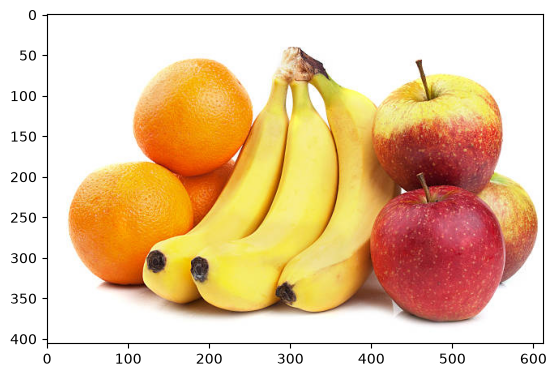

In [15]:
exercise_image = get_image("./data/fruits.jpg")
plt.imshow(exercise_image)

## **Zadanie: sprawdź jak będzie wyglądała predykcja dla powyższego obrazka**

In [16]:
get_prediction_probabilities(exercise_image, inception_v3)

Class: banana                         | Probability: 0.991837
Class: orange                         | Probability: 0.006961
Class: lemon                          | Probability: 0.000621
Class: pineapple                      | Probability: 0.000162
Class: Granny Smith                   | Probability: 0.000160
Class: pomegranate                    | Probability: 0.000060
Class: custard apple                  | Probability: 0.000041
Class: grocery store                  | Probability: 0.000034
Class: fig                            | Probability: 0.000010
Class: shopping basket                | Probability: 0.000010
Class: crate                          | Probability: 0.000009
Class: zucchini                       | Probability: 0.000008
Class: hook                           | Probability: 0.000005
Class: cucumber                       | Probability: 0.000004
Class: hamper                         | Probability: 0.000003


# **Model Inception-v3 - wyjaśnienie**

Chcemy wiedzieć dlaczego klasa `Bernese_mountain_dog` została uznana przez sieć neuronową za najbardziej prawdopodobną (to znaczy - które piksele obrazka o tym zadecydowały). W tym celu właśnie wykorzystamy LIME.

W jaki sposób działa LIME na obrazkach?
1. Na wejściu wymagany jest oryginalny obrazek.
2. Wejściowy obrazek jest delikatnie przekształcany wiele razy, dzięki czemu otrzymujemy wiele podobnych (ale nie takich samych!) obrazków.
3. Dodatkowo na wejście musimy podać funkcję, która każdemu takiemu przekształceniu nada prawdopodobieństwo przynależności do danej klasy. Jest to wymagane ponieważ LIME jest niezależny od żadnych narzędzi i modeli.

In [17]:
explainer = lime_image.LimeImageExplainer()

In [18]:
explanation = explainer.explain_instance(
    image=lime_transformer(image_to_classify), 
    classifier_fn=partial(predict_batch, inception_v3),
    top_labels=5,
    num_samples=1000)

100%|██████████| 1000/1000 [00:33<00:00, 30.06it/s]


Mając te dane możemy teraz sprawdzić które kategorie są najbardziej prawdopodobne

In [19]:
for index in explanation.top_labels:
    print(f"{class_names[index]}")

Bernese mountain dog
EntleBucher
Appenzeller
Greater Swiss Mountain dog
Gordon setter


Zobaczmy co wpłynęło na wybranie `Bernese_mountain_dog` jako najbardziej prawdopodobnej klasy.

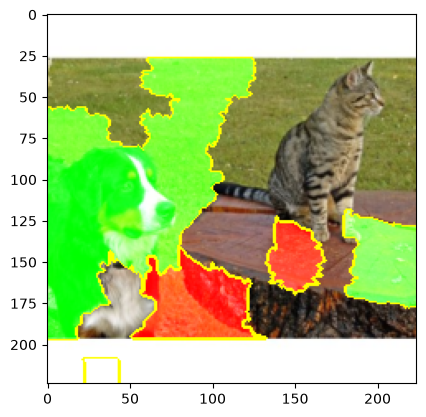

In [20]:
image, mask = explanation.get_image_and_mask(
    label=explanation.top_labels[0],
    positive_only=False,
    negative_only=False,
    num_features=10,
    hide_rest=False)
boundaries = mark_boundaries(image, mask)
plt.imshow(boundaries)

## **Zadanie: zmień wartość NUM_FEATURES i zaobserwuj jak zmienia się mapowanie**
NUM_FEATURES najlepiej zmieniać w zakresie 1:50

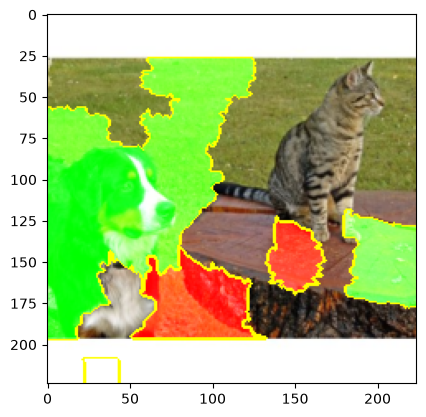

In [21]:
NUM_FEATURES = 10

image, mask = explanation.get_image_and_mask(
    label=explanation.top_labels[0],
    positive_only=False,
    negative_only=False,
    num_features=NUM_FEATURES,
    hide_rest=False)
boundaries = mark_boundaries(image, mask)
plt.imshow(boundaries)

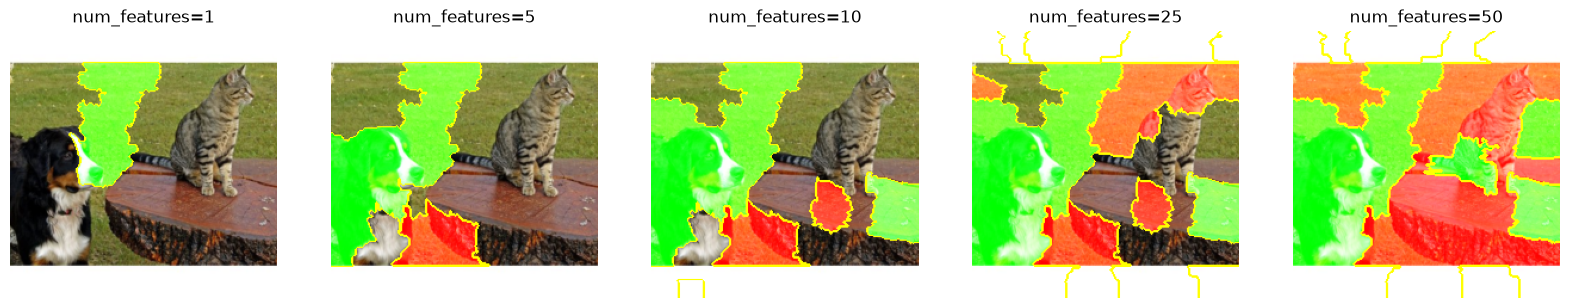

In [22]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, n in zip(axes, [1, 5, 10, 25, 50]):
    image, mask = explanation.get_image_and_mask(
        label=explanation.top_labels[0],
        positive_only=False, negative_only=False,
        num_features=n, hide_rest=False)
    ax.imshow(mark_boundaries(image, mask))
    ax.set_title(f"num_features={n}")
    ax.axis("off")
plt.show()

Przy małym NUM_FEATURES zaznaczone są tylko najważniejsze superpiksele (głowa psa i trawa obok), a przy dużym prawie cały obraz, łącznie z kotem i stołem, które przemawiają przeciw klasie.

Zielone fragmenty oznaczają "superpiksele", które pozytywnie wpływają na predykowaną klasę. Czerwone fragmenty wpływają negatywnie.

## **Zadanie-pytanie: co to właściwie jest superpiksel?**
Zbiór pikseli posiadających jakieś podobne cechy, które explainer uznał za istotne w kontekście predykcji modelu
## **Zadanie-pytanie: czy jeden superpiksel ma odzwierciedlenie w jednym pikselu z obrazka?**
Nie zawsze, może to być więcej niż 1 piksel

Zobaczmy jak to się prezentuje dla drugiej najbardziej prawdopodobnej klasy, czyli `EntleBucher`, która jednak otrzymała jedyne 3.8%.

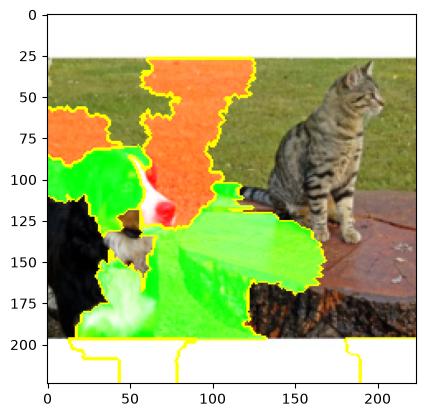

In [23]:
image, mask = explanation.get_image_and_mask(
    label=explanation.top_labels[1],
    positive_only=False,
    negative_only=False,
    num_features=10,
    hide_rest=False)
boundaries = mark_boundaries(image, mask)
plt.imshow(boundaries)

Ustawiając wartości `hide_rest` oraz `positive_only` na `True` jesteśmy w stanie zostawić tylko te piksele, które potwierdzały przynależność do danej klasy <br>
Musimy jednak pamiętać o przeskalowaniu rezultatu przy pomocy `(boundaries).astype(np.uint8)`

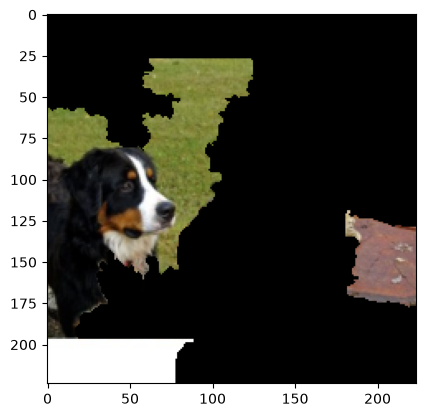

In [24]:
image, mask = explanation.get_image_and_mask(
    label=explanation.top_labels[0],
    positive_only=True,
    negative_only=False,
    num_features=10,
    hide_rest=True)
boundaries = mark_boundaries(image, mask)
plt.imshow((boundaries).astype(np.uint8))

Możemy również zostawić tylko te piksele, które zaprzeczały przynależności do danej klasy

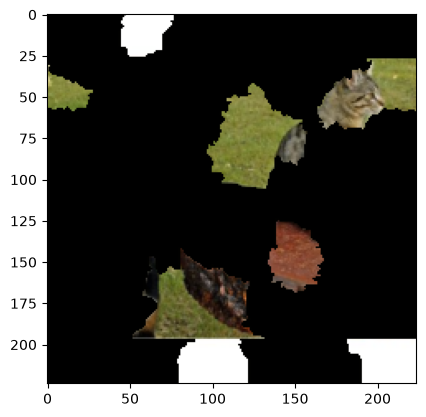

In [25]:
image, mask = explanation.get_image_and_mask(
    label=explanation.top_labels[0],
    positive_only=False,
    negative_only=True,
    num_features=10,
    hide_rest=True)
boundaries = mark_boundaries(image, mask)
cropped_image_ndarray = (boundaries).astype(np.uint8)
plt.imshow(cropped_image_ndarray)

A następnie sprawdzić co model sądzi o tak wyciętym obrazku

In [26]:
cropped_image_pil = Image.fromarray(cropped_image_ndarray)

get_prediction_probabilities(cropped_image_pil, inception_v3)

Class: kimono                         | Probability: 0.500738
Class: groom                          | Probability: 0.391070
Class: bow tie                        | Probability: 0.022115
Class: suit                           | Probability: 0.010533
Class: jigsaw puzzle                  | Probability: 0.008891
Class: academic gown                  | Probability: 0.007317
Class: mortarboard                    | Probability: 0.006348
Class: feather boa                    | Probability: 0.006145
Class: torch                          | Probability: 0.004680
Class: abaya                          | Probability: 0.002915
Class: komondor                       | Probability: 0.002147
Class: conch                          | Probability: 0.002061
Class: jersey                         | Probability: 0.002045
Class: tray                           | Probability: 0.001559
Class: daisy                          | Probability: 0.001444


I jak go teraz widzi model

In [27]:
cropped_image_explanation = explainer.explain_instance(
    image=lime_transformer(cropped_image_pil), 
    classifier_fn=partial(predict_batch, inception_v3),
    top_labels=5,
    num_samples=1000)

100%|██████████| 1000/1000 [00:33<00:00, 29.64it/s]


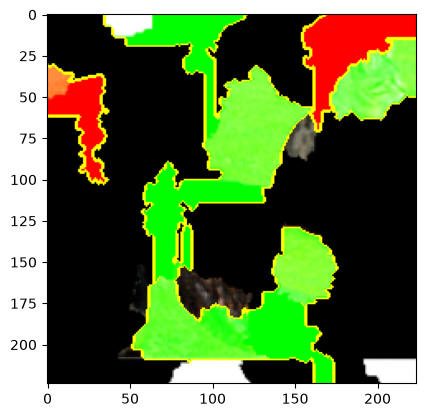

In [28]:
image, mask = cropped_image_explanation.get_image_and_mask(
    label=cropped_image_explanation.top_labels[0],
    positive_only=False,
    negative_only=False,
    num_features=10,
    hide_rest=False)
boundaries = mark_boundaries(image, mask)
plt.imshow(boundaries)

# **Model Inception-v3 - porównanie z AlexNet**

Przetestujmy działanie na innym modelu - `AlexNet`

In [29]:
alex_weights = models.AlexNet_Weights.DEFAULT
alexnet = models.alexnet(weights=alex_weights)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to C:\Users\Lukasz/.cache\torch\hub\checkpoints\alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:02<00:00, 93.1MB/s] 


In [30]:
explanation_alexnet = explainer.explain_instance(
    image=lime_transformer(image_to_classify), 
    classifier_fn=partial(predict_batch, alexnet),
    top_labels=5,
    num_samples=1000)

100%|██████████| 1000/1000 [00:08<00:00, 112.24it/s]


In [31]:
for index_alex, index_inception in zip(explanation_alexnet.top_labels, explanation.top_labels):
        print(f"{class_names[index_alex]:30} | {class_names[index_inception]:30}")

Bernese mountain dog           | Bernese mountain dog          
EntleBucher                    | EntleBucher                   
Greater Swiss Mountain dog     | Appenzeller                   
Appenzeller                    | Greater Swiss Mountain dog    
basset                         | Gordon setter                 


Jak widać, klasy nieco się różnią, ale TOP 1 pozostaje takie samo.

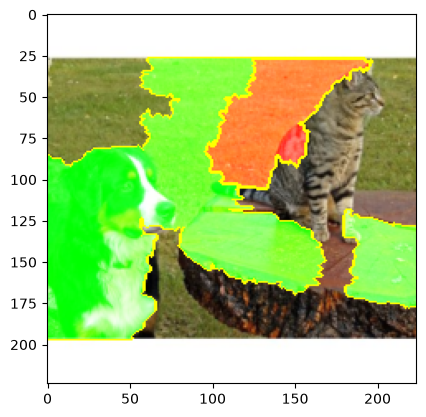

In [32]:
image, mask = explanation_alexnet.get_image_and_mask(
    label=explanation_alexnet.top_labels[0],
    positive_only=False,
    negative_only=False,
    num_features=10,
    hide_rest=False)
boundaries = mark_boundaries(image, mask)
plt.imshow(boundaries)

Wyjaśnienie dla `AlexNet` jak się można było spodziewać - też się różni, jednak w dalszym ciągu do klasyfikacji psa istotny jest... pies :)

## **Zadanie: porównaj predykcje obrazka dla modeli inception_v3 oraz alexnet**

In [33]:
print("inception_v3")
get_prediction_probabilities(image_to_classify, inception_v3)
print()
print("alexnet")
get_prediction_probabilities(image_to_classify, alexnet)

inception_v3
Class: Bernese mountain dog           | Probability: 0.935930
Class: EntleBucher                    | Probability: 0.038448
Class: Appenzeller                    | Probability: 0.023756
Class: Greater Swiss Mountain dog     | Probability: 0.001818
Class: Gordon setter                  | Probability: 0.000009
Class: Blenheim spaniel               | Probability: 0.000007
Class: English springer               | Probability: 0.000002
Class: tabby                          | Probability: 0.000002
Class: robin                          | Probability: 0.000001
Class: guinea pig                     | Probability: 0.000001
Class: amphibian                      | Probability: 0.000001
Class: Japanese spaniel               | Probability: 0.000001
Class: African grey                   | Probability: 0.000001
Class: Brittany spaniel               | Probability: 0.000001
Class: toucan                         | Probability: 0.000001

alexnet
Class: Bernese mountain dog           | Probabil

Inception_v3 i AlexNet wskazują tę samą rasę psa, ale inception jest dużo pewniejszy (0.94 vs 0.40), a AlexNet rozkłada prawdopodobieństwo między podobne rasy.

# **Zadanie domowe - wstęp**
W folderze `data` znajduje się zdjęcie amfibii:
![title](data/amfibia.jpg)


In [34]:
amphibious_vehicle = get_image("./data/amfibia.jpg")

100%|██████████| 1000/1000 [00:34<00:00, 29.19it/s]


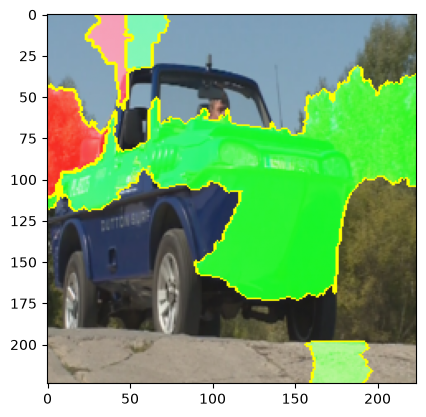

In [35]:
weights = models.Inception_V3_Weights.DEFAULT
inception_v3 = models.inception_v3(weights=weights)

explanation_amhibious_vehicle_inception_v3 = explainer.explain_instance(
    image=lime_transformer(amphibious_vehicle), 
    classifier_fn=partial(predict_batch, inception_v3),
    top_labels=5,
    num_samples=1000)

image, mask = explanation_amhibious_vehicle_inception_v3.get_image_and_mask(
    label=explanation_amhibious_vehicle_inception_v3.top_labels[0],
    positive_only=False,
    negative_only=False,
    num_features=10,
    hide_rest=False)
boundaries = mark_boundaries(image, mask)
plt.imshow(boundaries)

Model `inception_v3` jak i jego wyjaśnienie rzeczywiście sugerują amfibię jako najbardziej prawdopodobną klasę:

In [36]:
for index in explanation_amhibious_vehicle_inception_v3.top_labels:
    print(class_names[index])

amphibian
convertible
racer
car wheel
golfcart


In [37]:
amphibian_idx = class_names.index("amphibian")
amphibious_arr = lime_transformer(amphibious_vehicle)

def top_k(model, arr, k=5):
    with torch.no_grad():
        p = predict_batch(model, [arr])[0]
    idx = p.argsort()[::-1][:k]
    return [(class_names[i], float(p[i])) for i in idx]

def explain_and_show(model, arr, title, num_features=10):
    with torch.no_grad():
        exp = explainer.explain_instance(
            image=arr,
            classifier_fn=partial(predict_batch, model),
            top_labels=5,
            num_samples=1000)
    print(title, "| top labels:", [class_names[i] for i in exp.top_labels])
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (pos, neg, name) in zip(axes, [(False, False, "all"),
                                           (True, False, "positive only"),
                                           (False, True, "negative only")]):
        image, mask = exp.get_image_and_mask(
            label=exp.top_labels[0], positive_only=pos, negative_only=neg,
            num_features=num_features, hide_rest=(pos or neg))
        b = mark_boundaries(image, mask)
        ax.imshow(b.astype(np.uint8) if (pos or neg) else b)
        ax.set_title(f"{title}: {class_names[exp.top_labels[0]]} ({name})")
        ax.axis("off")
    plt.show()
    return exp

# Zadanie #1

Użyj dwóch różnych sieci neuronowych (poza inception_v3, którego przykład jest powyżej) do wygenerowania wyjaśnień.<br>
(skorzystaj z modułu torchvision: https://pytorch.org/vision/stable/models.html). Przeanalizuj uzyskane wyjaśnienia - które elementy obrazu sprzyjały danej predykcji, a które nie?

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\Lukasz/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 81.6MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Lukasz/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 56.0MB/s]


resnet50 [('amphibian', 0.39738789200782776), ('racer', 0.030149372294545174), ('convertible', 0.019455984234809875), ('pickup', 0.011190594173967838), ('car wheel', 0.009683161042630672)]


100%|██████████| 1000/1000 [00:38<00:00, 25.73it/s]


resnet50 | top labels: ['amphibian', 'racer', 'convertible', 'pickup', 'car wheel']


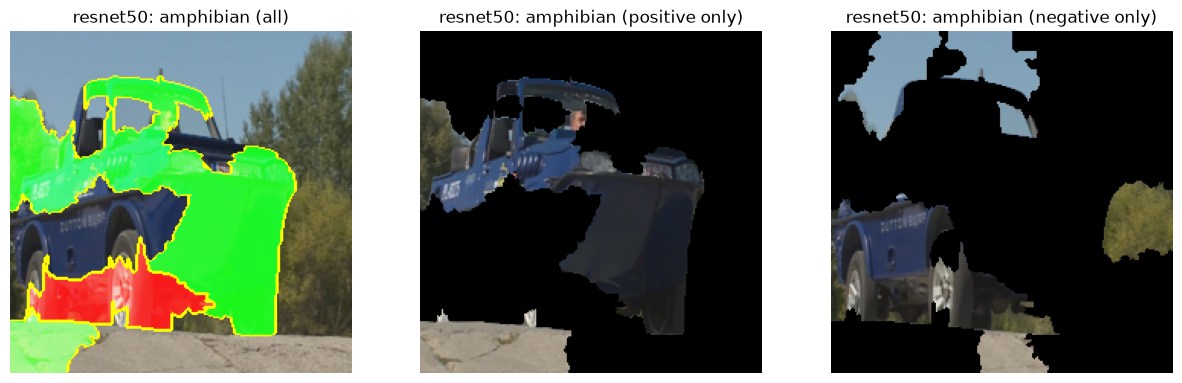

efficientnet_b0 [('amphibian', 0.7442877292633057), ('racer', 0.08160832524299622), ('tow truck', 0.04263955354690552), ('convertible', 0.01472492702305317), ('car wheel', 0.014170545153319836)]


100%|██████████| 1000/1000 [00:14<00:00, 66.99it/s]


efficientnet_b0 | top labels: ['amphibian', 'racer', 'tow truck', 'convertible', 'car wheel']


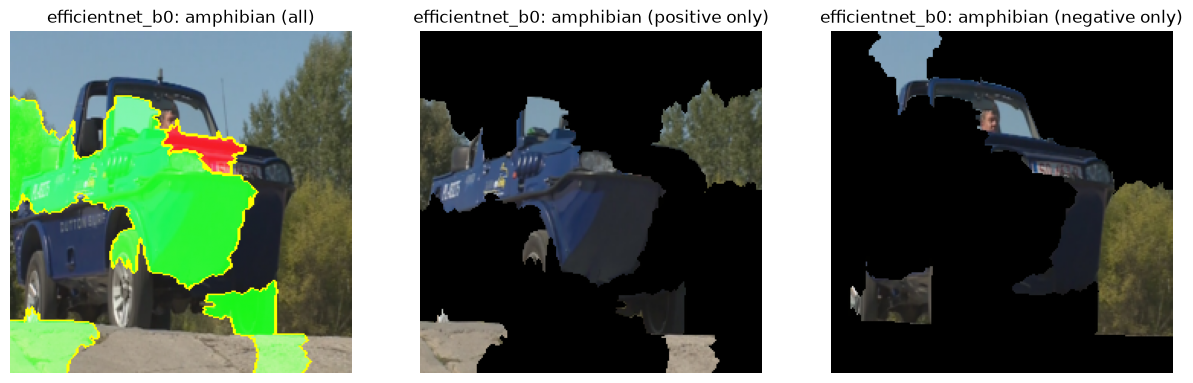

In [38]:
resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
effnet = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

nets = {"resnet50": resnet, "efficientnet_b0": effnet}

explanations = {}
for name, net in nets.items():
    print(name, top_k(net, amphibious_arr))
    explanations[name] = explain_and_show(net, amphibious_arr, name)

ResNet-50 (0.40) i EfficientNet-B0 (0.74) również przewidują amfibię. Wszystkie sieci opierają decyzję głównie na łódkowatym przodzie i kadłubie pojazdu oraz na kabinie, czyli na tym, co odróżnia amfibię od zwykłego auta. Koła, bok karoserii i tło przemawiają raczej przeciw. Wyjaśnienia są intuicyjne.

# Zadanie #2

Zmodyfikuj oryginalny obrazek w taki sposób, żeby najbardziej prawdopodobną klasą dla każdej z tych sieci **nie była** amfibia a jakiś inny pojazd (np. samochód). W tym celu możesz "zasłonić" czarnym kwadratem (wartość 0 w macierzy reprezentującej obraz) obszary istotne przy klasyfikacji. <br>
Wygeneruj i przeanalizuj wyjaśnienia jak w Zadaniu 1.

0 {'inception_v3': ('amphibian', 0.9999986886978149), 'resnet50': ('amphibian', 0.39738789200782776), 'efficientnet_b0': ('amphibian', 0.7442877292633057)}


100%|██████████| 1000/1000 [00:31<00:00, 32.07it/s]


1 {'inception_v3': ('amphibian', 0.9999512434005737), 'resnet50': ('amphibian', 0.06816302239894867), 'efficientnet_b0': ('amphibian', 0.32800284028053284)}


100%|██████████| 1000/1000 [00:30<00:00, 33.08it/s]


2 {'inception_v3': ('amphibian', 0.9950632452964783), 'resnet50': ('amphibian', 0.16413071751594543), 'efficientnet_b0': ('amphibian', 0.7143800854682922)}


100%|██████████| 1000/1000 [00:32<00:00, 30.76it/s]


3 {'inception_v3': ('tow truck', 0.751237690448761), 'resnet50': ('amphibian', 0.13401977717876434), 'efficientnet_b0': ('amphibian', 0.619305431842804)}


100%|██████████| 1000/1000 [00:39<00:00, 25.14it/s]


4 {'inception_v3': ('pickup', 0.8305800557136536), 'resnet50': ('pickup', 0.09714063256978989), 'efficientnet_b0': ('pickup', 0.445519357919693)}


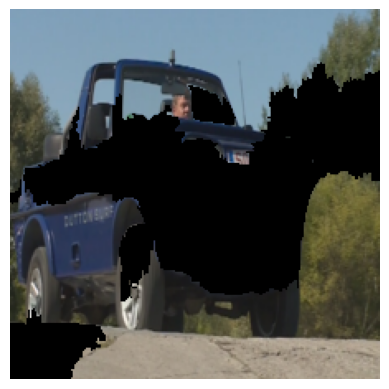

In [39]:
all_nets = {"inception_v3": inception_v3, **nets}

def occlude_top_superpixels(model, arr, label, n=2):
    with torch.no_grad():
        exp = explainer.explain_instance(
            image=arr, classifier_fn=partial(predict_batch, model),
            top_labels=5, num_samples=1000)
    positive = [seg for seg, w in exp.local_exp[label] if w > 0][:n]
    out = arr.copy()
    for seg in positive:
        out[exp.segments == seg] = 0
    return out

occluded = amphibious_arr.copy()
for step in range(10):
    tops = {name: top_k(net, occluded, 1)[0] for name, net in all_nets.items()}
    print(step, tops)
    still_amphibian = [name for name, (cls, _) in tops.items() if cls == "amphibian"]
    if not still_amphibian:
        break
    occluded = occlude_top_superpixels(all_nets[still_amphibian[0]], occluded, amphibian_idx)

plt.imshow(occluded); plt.axis("off"); plt.show()

100%|██████████| 1000/1000 [00:31<00:00, 31.57it/s]


inception_v3 (occluded) | top labels: ['pickup', 'amphibian', 'tow truck', 'snowplow', 'convertible']


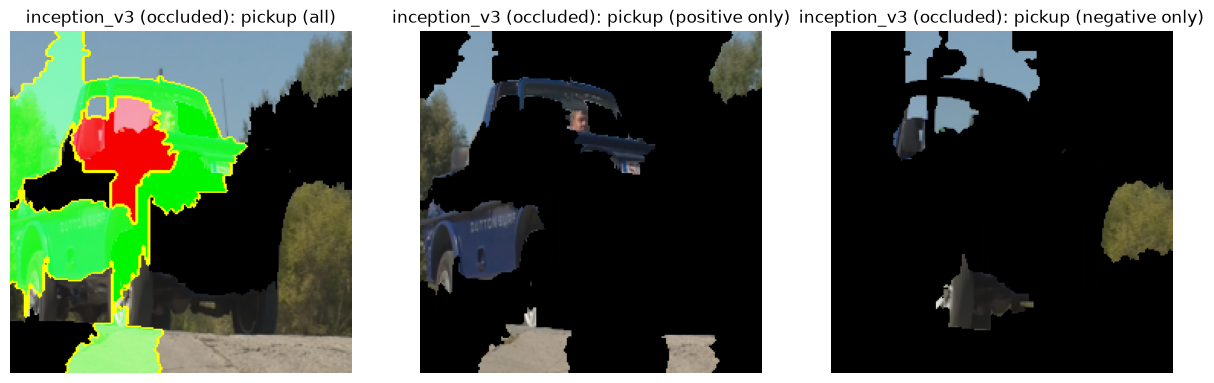

100%|██████████| 1000/1000 [00:38<00:00, 26.26it/s]


resnet50 (occluded) | top labels: ['pickup', 'tow truck', 'amphibian', 'jeep', 'Model T']


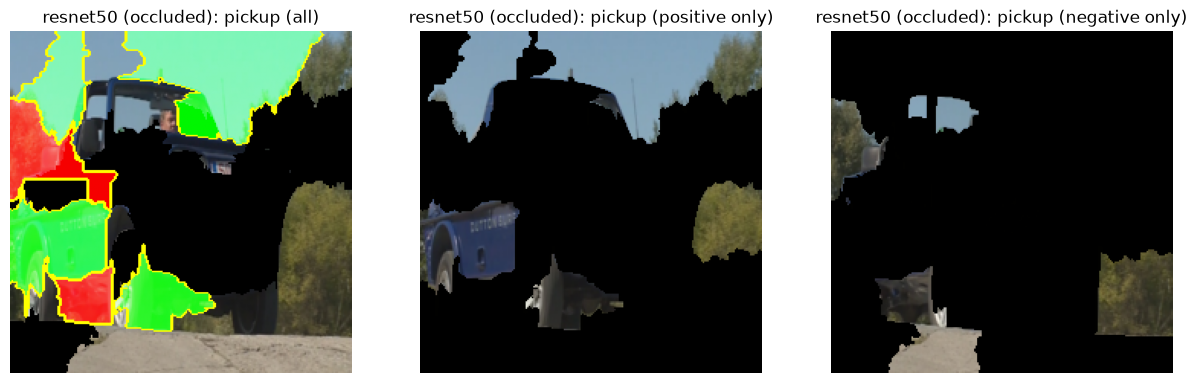

100%|██████████| 1000/1000 [00:14<00:00, 67.42it/s]


efficientnet_b0 (occluded) | top labels: ['pickup', 'convertible', 'amphibian', 'tow truck', 'jeep']


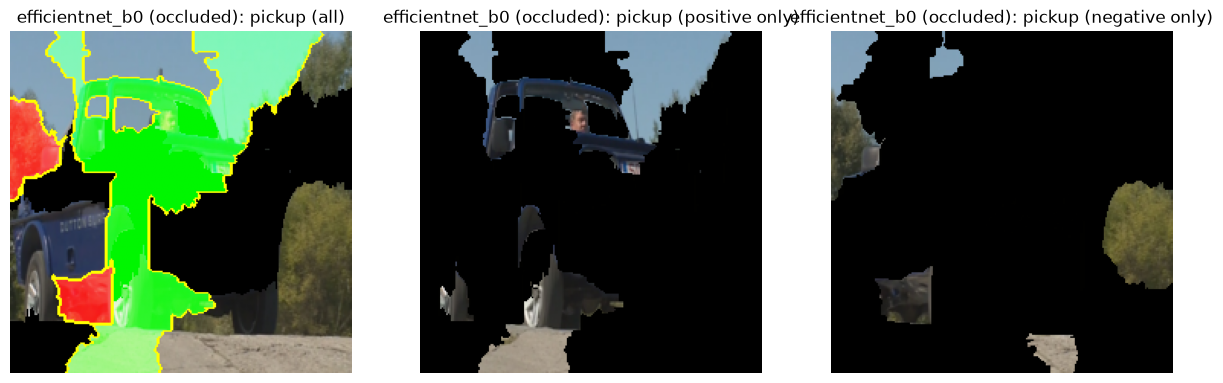

In [40]:
occluded_explanations = {name: explain_and_show(net, occluded, name + " (occluded)") for name, net in all_nets.items()}

Iteracyjnie zaczerniałem superpiksele najmocniej przemawiające za amfibią. Po 4 krokach wszystkie sieci przewidują pickup. Zasłonięty został kadłub i przód, a pozostała kabina z kołem wygląda jak zwykły pickup, i to właśnie na nią wskazują teraz wyjaśnienia. Najdłużej opierał się inception_v3, a zasłanianie dobrane pod jedną sieć nie zawsze pomagało pozostałym.

# Zadanie #3

Ponownie zmodyfikuj oryginalny obraz, ale tym razem zaszumiając go w losowy sposób (przykładowa implementacja: https://www.geeksforgeeks.org/add-a-salt-and-pepper-noise-to-an-image-with-python/). Czy najbardziej prawdopodobna klasa zmienia się wraz ze zmianą szumu? Przetestuj dla każdego z modeli.

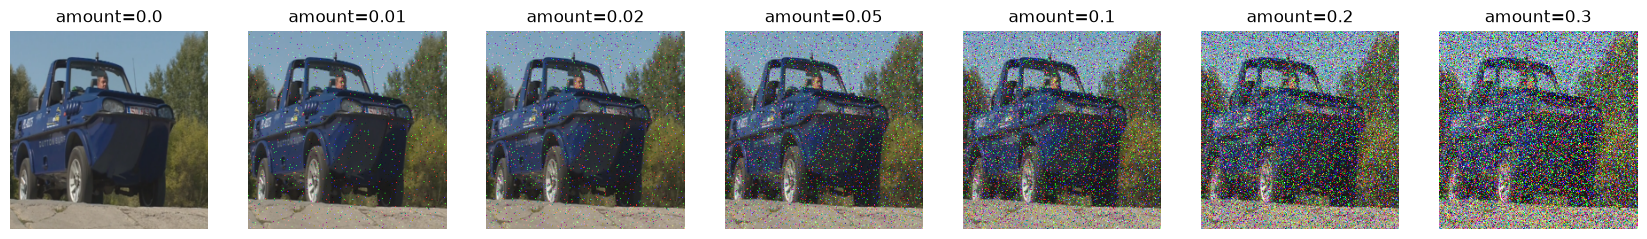

--- inception_v3
amount=0.0   | amphibian                 | 1.000
amount=0.01  | amphibian                 | 1.000
amount=0.02  | amphibian                 | 0.994
amount=0.05  | amphibian                 | 0.999
amount=0.1   | tractor                   | 0.772
amount=0.2   | Model T                   | 0.695
amount=0.3   | tractor                   | 0.850
--- resnet50
amount=0.0   | amphibian                 | 0.403
amount=0.01  | amphibian                 | 0.271
amount=0.02  | jeep                      | 0.171
amount=0.05  | amphibian                 | 0.185
amount=0.1   | amphibian                 | 0.216
amount=0.2   | amphibian                 | 0.083
amount=0.3   | barn spider               | 0.067
--- efficientnet_b0
amount=0.0   | amphibian                 | 0.751
amount=0.01  | amphibian                 | 0.378
amount=0.02  | amphibian                 | 0.233
amount=0.05  | pickup                    | 0.273
amount=0.1   | tractor                   | 0.193
amount=0.2   | mong

In [41]:
from skimage.util import random_noise

amounts = [0.0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3]

noisy_images = {}
for a in amounts:
    noisy = random_noise(amphibious_arr, mode="s&p", amount=a, rng=0)
    noisy_images[a] = (noisy * 255).astype(np.uint8)

fig, axes = plt.subplots(1, len(amounts), figsize=(3 * len(amounts), 3))
for ax, a in zip(axes, amounts):
    ax.imshow(noisy_images[a]); ax.set_title(f"amount={a}"); ax.axis("off")
plt.show()

for name, net in all_nets.items():
    print(f"--- {name}")
    for a in amounts:
        cls, p = top_k(net, noisy_images[a], 1)[0]
        print(f"amount={a:<5} | {cls:<25} | {p:.3f}")

100%|██████████| 1000/1000 [00:30<00:00, 32.79it/s]

inception_v3 (s&p 0.1) | top labels: ['tractor', 'thresher', 'harvester', 'snowplow', 'amphibian']


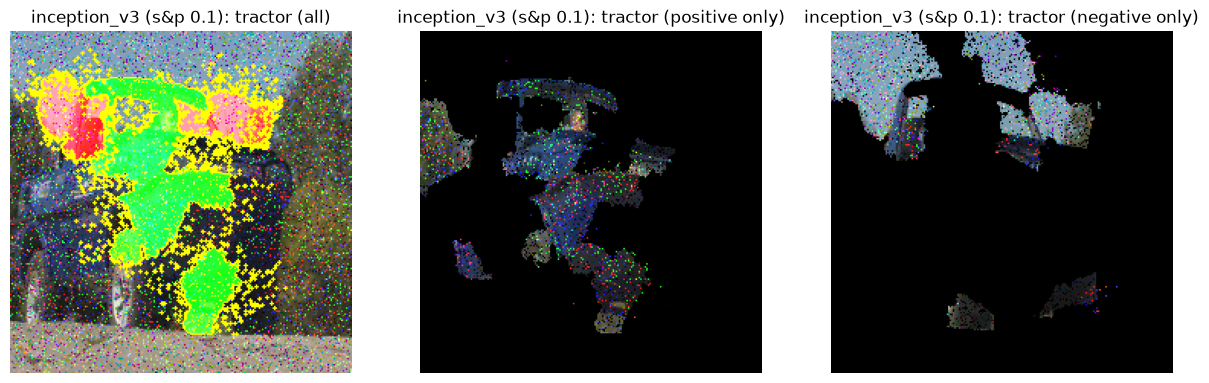

100%|██████████| 1000/1000 [00:38<00:00, 25.91it/s]


resnet50 (s&p 0.1) | top labels: ['amphibian', 'pickup', 'wreck', 'tow truck', 'snowplow']


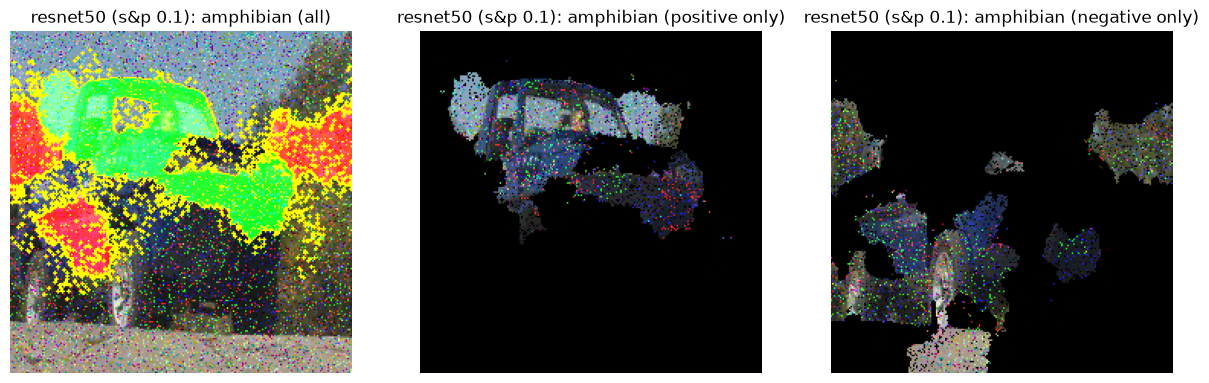

100%|██████████| 1000/1000 [00:14<00:00, 68.75it/s]


efficientnet_b0 (s&p 0.1) | top labels: ['tractor', 'forklift', 'harvester', 'plow', 'amphibian']


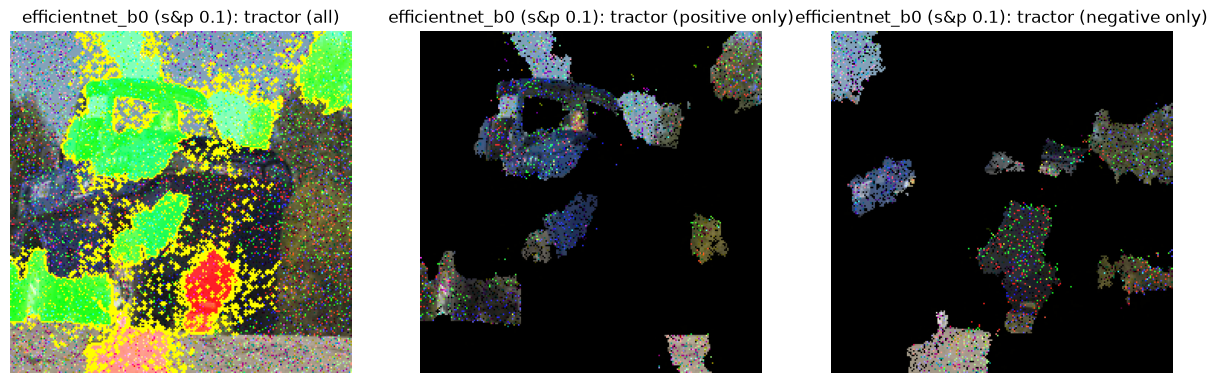

In [42]:
for name, net in all_nets.items():
    explain_and_show(net, noisy_images[0.1], f"{name} (s&p 0.1)")

Klasa zmienia się wraz z poziomem szumu. Inception_v3 trzyma amfibię do amount=0.05, potem przechodzi na tractor i Model T. ResNet-50 utrzymuje amfibię najdłużej (do 0.2), ale z bardzo niską pewnością. EfficientNet-B0 jest najmniej odporny: już przy 0.05 przechodzi na pickup, a przy dużym szumie na przypadkowe klasy (mongoose, goose). Szum psuje też segmentację, więc superpiksele w wyjaśnieniach są poszarpane, choć sieci nadal patrzą głównie na kabinę i przód pojazdu.